In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json

from pathlib import Path

C:\Users\praja\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.4' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\praja\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [3]:
project_dir = Path(
    r"C:\Users\praja\functional-connectivity\neuroscience_project"
)

results_dir = project_dir / "results"

distance_matrix = np.load(
    results_dir / "distance_matrix.npy"
)

H0 = np.load(
    results_dir / "persistence_H0.npy"
)

H1 = np.load(
    results_dir / "persistence_H1.npy"
)

print("Distance matrix:", distance_matrix.shape)
print("H0:", H0.shape)
print("H1:", H1.shape)

Distance matrix: (74, 74)
H0: (74, 2)
H1: (18, 2)


In [5]:
D = np.asarray(distance_matrix, dtype=float)

print("All finite:", np.isfinite(D).all())
print("Symmetric:", np.allclose(D, D.T, atol=1e-8))
print("Diagonal zero:", np.allclose(np.diag(D), 0, atol=1e-8))
print("Minimum distance:", D.min())
print("Maximum distance:", D.max())

assert D.shape == (74, 74)
assert np.isfinite(D).all()
assert np.allclose(D, D.T, atol=1e-8)
assert np.allclose(np.diag(D), 0, atol=1e-8)
assert D.min() >= -1e-8

D = (D + D.T) / 2
np.fill_diagonal(D, 0)

print("DISTANCE MATRIX VALIDATED")

All finite: True
Symmetric: True
Diagonal zero: True
Minimum distance: 0.0
Maximum distance: 1.5008524278813047
DISTANCE MATRIX VALIDATED


In [7]:
def validate_diagram(diagram):

    diagram = np.asarray(diagram, dtype=float)

    assert diagram.ndim == 2
    assert diagram.shape[1] == 2
    assert np.isfinite(diagram[:, 0]).all()
    assert not np.isnan(diagram[:, 1]).any()
    assert np.all(diagram[:, 1] >= diagram[:, 0])

    return diagram


H0 = validate_diagram(H0)
H1 = validate_diagram(H1)

print("H0 intervals:", len(H0))
print("H1 intervals:", len(H1))

print("H0 infinite deaths:", np.isinf(H0[:, 1]).sum())
print("H1 infinite deaths:", np.isinf(H1[:, 1]).sum())

print("PERSISTENCE DIAGRAMS VALIDATED")

H0 intervals: 74
H1 intervals: 18
H0 infinite deaths: 1
H1 infinite deaths: 0
PERSISTENCE DIAGRAMS VALIDATED


In [9]:
upper_distances = D[np.triu_indices(74, k=1)]

quantiles = [0.10, 0.25, 0.50, 0.75, 0.90]

thresholds = np.unique(
    np.quantile(upper_distances, quantiles)
)

print("Filtration thresholds:")

for threshold in thresholds:
    print(round(float(threshold), 5))

Filtration thresholds:
0.53945
0.66617
0.79915
0.95421
1.14981


In [11]:
def count_components(adjacency):

    n = len(adjacency)
    visited = np.zeros(n, dtype=bool)
    components = 0

    for start in range(n):

        if visited[start]:
            continue

        components += 1
        stack = [start]
        visited[start] = True

        while stack:

            node = stack.pop()

            neighbors = np.flatnonzero(
                adjacency[node] & ~visited
            )

            visited[neighbors] = True
            stack.extend(neighbors.tolist())

    return components


records = []

for eps in thresholds:

    adjacency = D <= eps
    np.fill_diagonal(adjacency, False)

    edges = int(np.count_nonzero(
        np.triu(adjacency, k=1)
    ))

    components = count_components(adjacency)

    beta0 = int(np.sum(
        (H0[:, 0] <= eps) & (H0[:, 1] > eps)
    ))

    beta1 = int(np.sum(
        (H1[:, 0] <= eps) & (H1[:, 1] > eps)
    ))

    cycle_rank = edges - 74 + components

    records.append({
        "threshold": float(eps),
        "H0_Betti0": beta0,
        "Graph_components": components,
        "H0_matches_graph": beta0 == components,
        "H1_Betti1": beta1,
        "Graph_edges": edges,
        "Graph_cycle_rank": cycle_rank
    })


results_df = pd.DataFrame(records)

print(results_df.to_string(index=False))

 threshold  H0_Betti0  Graph_components  H0_matches_graph  H1_Betti1  Graph_edges  Graph_cycle_rank
  0.539447         17                17              True          2          271               214
  0.666167          6                 6              True          2          676               608
  0.799151          4                 4              True          1         1351              1281
  0.954212          4                 4              True          0         2026              1956
  1.149809          1                 1              True          0         2431              2358


In [13]:
summary = {
    "number_of_thresholds": len(thresholds),

    "H0_Betti0_min": int(
        results_df["H0_Betti0"].min()
    ),

    "H0_Betti0_max": int(
        results_df["H0_Betti0"].max()
    ),

    "H1_Betti1_min": int(
        results_df["H1_Betti1"].min()
    ),

    "H1_Betti1_max": int(
        results_df["H1_Betti1"].max()
    ),

    "H0_graph_validation": bool(
        results_df["H0_matches_graph"].all()
    ),

    "cycle_rank_min": int(
        results_df["Graph_cycle_rank"].min()
    ),

    "cycle_rank_max": int(
        results_df["Graph_cycle_rank"].max()
    )
}

print(json.dumps(summary, indent=4))

{
    "number_of_thresholds": 5,
    "H0_Betti0_min": 1,
    "H0_Betti0_max": 17,
    "H1_Betti1_min": 0,
    "H1_Betti1_max": 2,
    "H0_graph_validation": true,
    "cycle_rank_min": 214,
    "cycle_rank_max": 2358
}


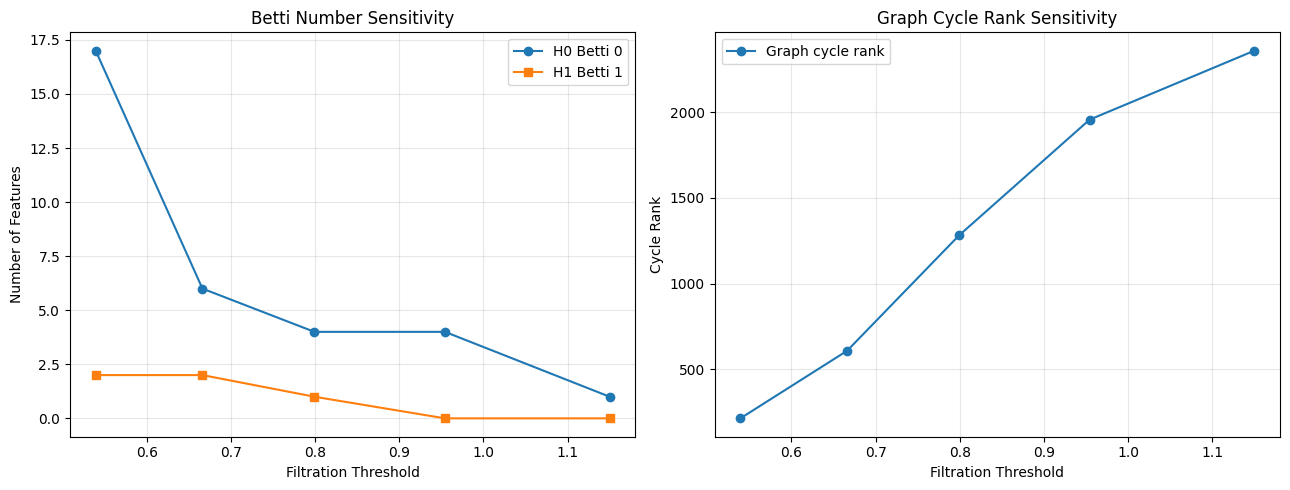

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    thresholds,
    results_df["H0_Betti0"],
    marker="o",
    label="H0 Betti 0"
)

axes[0].plot(
    thresholds,
    results_df["H1_Betti1"],
    marker="s",
    label="H1 Betti 1"
)

axes[0].set_title("Betti Number Sensitivity")
axes[0].set_xlabel("Filtration Threshold")
axes[0].set_ylabel("Number of Features")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    thresholds,
    results_df["Graph_cycle_rank"],
    marker="o",
    label="Graph cycle rank"
)

axes[1].set_title("Graph Cycle Rank Sensitivity")
axes[1].set_xlabel("Filtration Threshold")
axes[1].set_ylabel("Cycle Rank")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    results_dir / "milestone8_robustness.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [17]:
results_df.to_csv(
    results_dir / "milestone8_threshold_sensitivity.csv",
    index=False
)

with open(
    results_dir / "milestone8_robustness_summary.json",
    "w"
) as f:

    json.dump(summary, f, indent=4)

print("MILESTONE 8 COMPLETED")
print("Results saved in:", results_dir)

MILESTONE 8 COMPLETED
Results saved in: C:\Users\praja\functional-connectivity\neuroscience_project\results
